# Modul 1 — Eksplorasi & Replikasi Dashboard
**Tujuan:** (a) membuktikan angka Python = angka Power BI, (b) memperdalam apa yang tidak bisa dijawab dashboard: korelasi, pola hari, dan dekomposisi selisih output.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140, "display.max_columns", 30)
XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
h, log, qc, pr = S["Data_Harian"], S["Downtime_Log"], S["QC_Lab"], S["Proses_Harian"]
for df in (h, log, qc, pr): df["Tanggal"] = pd.to_datetime(df["Tanggal"])
NAMA_BULAN = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun", 7: "Jul", 8: "Agu", 9: "Sep"}

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


## 1. KPI utama (cocokkan dengan kartu di Power BI)
Target 17.000 t/bulan × 9 bulan = 153.000 t.

In [ ]:
TARGET_BULANAN = 17000
target = TARGET_BULANAN * 9
katoda = h.Katoda_Cu_t.sum()
recovery = h.Katoda_Cu_t.sum() / h.Cu_Masuk_t.sum() * 100          # rasio total, BUKAN rata-rata persen harian
availability = h.Jam_Operasi.sum() / (24 * len(h)) * 100
grade_a = (qc.Status_Mutu == "Grade A").sum()
print(f"Katoda total      : {katoda:,.1f} t")
print(f"Target 9 bulan    : {target:,} t   selisih {katoda-target:+,.0f} t ({(katoda/target-1)*100:+.1f}%)")
print(f"Recovery          : {recovery:.1f}%   (rata-rata sederhana harian = {h.Recovery_Persen.mean():.2f}%)")
print(f"Availability      : {availability:.1f}%")
print(f"Grade A           : {grade_a}/{len(qc)} = {grade_a/len(qc)*100:.1f}%")

Katoda total      : 156,326.2 t
Target 9 bulan    : 153,000 t   selisih +3,326 t (+2.2%)
Recovery          : 98.1%   (rata-rata sederhana harian = 98.15%)
Availability      : 95.0%
Grade A           : 258/273 = 94.5%


**Catatan penting:** rata-rata dari persentase harian ≠ rasio total. Di DAX, ini sama dengan membedakan `AVERAGE(kolom)` vs `DIVIDE(SUM(a), SUM(b))`. Dashboard memakai rasio total.

## 2. Ringkasan bulanan

In [ ]:
h["Bulan_Nama"] = h.Bulan.map(NAMA_BULAN)
bln = h.groupby("Bulan").agg(Hari=("Tanggal", "size"), Katoda_t=("Katoda_Cu_t", "sum"), Downtime_jam=("Jam_Downtime", "sum"),
Cu_Masuk_t=("Cu_Masuk_t", "sum"), Energi_MWh=("Energi_MWh", "sum"), Jam_Operasi=("Jam_Operasi", "sum"))
TARGET_HARIAN = TARGET_BULANAN * 9 / len(h)        # 153.000 t / 273 hari = 560,44 t/hari
bln["Target_t"] = TARGET_HARIAN * bln.Hari
bln["vs_Target_t"] = bln.Katoda_t - bln.Target_t
bln["vs_Target_%"] = bln.vs_Target_t / bln.Target_t * 100
bln["Recovery_%"] = bln.Katoda_t / bln.Cu_Masuk_t * 100
bln["Availability_%"] = bln.Jam_Operasi / (24 * bln.Hari) * 100
bln["Energi_per_t"] = bln.Energi_MWh / bln.Katoda_t
print(bln.round(2).drop(columns=["Cu_Masuk_t", "Jam_Operasi"]))

       Hari  Katoda_t  Downtime_jam  Energi_MWh  Target_t  vs_Target_t  vs_Target_%  Recovery_%  Availability_%  Energi_per_t
Bulan                                                                                                                        
1        31   18013.6          20.0       26208  17373.63       639.97         3.68       98.01           97.31          1.45
2        28   16118.5          16.0       23592  15692.31       426.19         2.72       98.26           97.62          1.46
3        31   18179.0          25.5       26755  17373.63       805.37         4.64       97.76           96.57          1.47
4        30   15818.0         102.5       23226  16813.19      -995.19        -5.92       98.35           85.76          1.47
5        31   18540.8          23.0       27202  17373.63      1167.17         6.72       98.28           96.91          1.47
6        30   16231.0          47.0       23820  16813.19      -582.19        -3.46       97.93           93.47       

## 3. Pareto penyebab downtime tidak terencana
Kumulatif harus dibagi **total seluruh penyebab** (setara `ALL(penyebab)` di DAX), bukan total dari bar yang tampil.

Kategori: ['Tidak Terjadwal' 'Terjadwal'] | kejadian tidak terencana: 58
Total tidak terencana: 177.5 jam
                              Jam  Persen  Kumulatif_%
Penyebab                                              
Trip kompresor udara         34.0    19.2         19.2
Gangguan tuyere              22.0    12.4         31.5
Kebocoran waste heat boiler  20.0    11.3         42.8
Gangguan demister            18.0    10.1         53.0
Trip jaringan listrik        14.5     8.2         61.1
Gangguan casting wheel       12.0     6.8         67.9
Gangguan rectifier           11.5     6.5         74.4
Kebocoran sel elektrolisis    9.0     5.1         79.4

Top-5 = 61.1% dari total


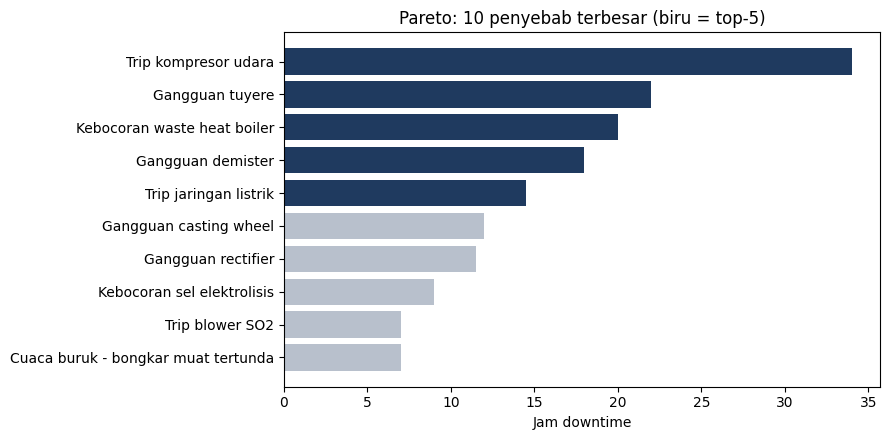

In [ ]:
tak = log[log.Kategori.str.contains("Tidak", case=False)]
print("Kategori:", log.Kategori.unique(), "| kejadian tidak terencana:", len(tak))
par = tak.groupby("Penyebab").Durasi_Jam.sum().sort_values(ascending=False).to_frame("Jam")
par["Persen"] = par.Jam / par.Jam.sum() * 100
par["Kumulatif_%"] = par.Persen.cumsum()
print(f"Total tidak terencana: {par.Jam.sum():.1f} jam")
print(par.head(8).round(1))
print(f"\nTop-5 = {par['Kumulatif_%'].iloc[4]:.1f}% dari total")

top = par.head(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
warna = ["#1F3A5F" if i < 5 else "#B8C0CC" for i in range(len(top))]
ax.barh(top.index[::-1], top.Jam[::-1], color=warna[::-1])
ax.set_xlabel("Jam downtime"); ax.set_title("Pareto: 10 penyebab terbesar (biru = top-5)")
plt.tight_layout(); plt.show()

## 4. Dekomposisi selisih output vs baseline (volume, grade, recovery)
Katoda bulan *m* = konsentrat × grade × recovery. Baseline = rata-rata **YTD per hari**. Tiap bulan, selisihnya diurai menjadi tiga efek yang **tepat berjumlah** selisih total:
- efek volume = (konsentrat_m − hari × D0) · g0 · r0
- efek grade  = konsentrat_m · (g_m − g0) · r0
- efek recovery = Cu_masuk_m · (r_m − r0)

       Efek_Volume  Efek_Grade  Efek_Recovery   Total
Bulan                                                
1            429.7      -142.2          -25.2   262.3
2            663.9      -597.8           18.9    85.0
3            226.0       274.3          -72.6   427.7
4          -1865.8       472.5           32.5 -1360.7
5            438.8       325.9           24.8   789.5
6           -280.1      -631.9          -35.6  -947.7
7           -375.1      -335.1           20.0  -690.2
8            450.4       -53.3           34.3   431.4
9            312.4       687.6            2.8  1002.8
Cek identitas (selisih maks): 0.0


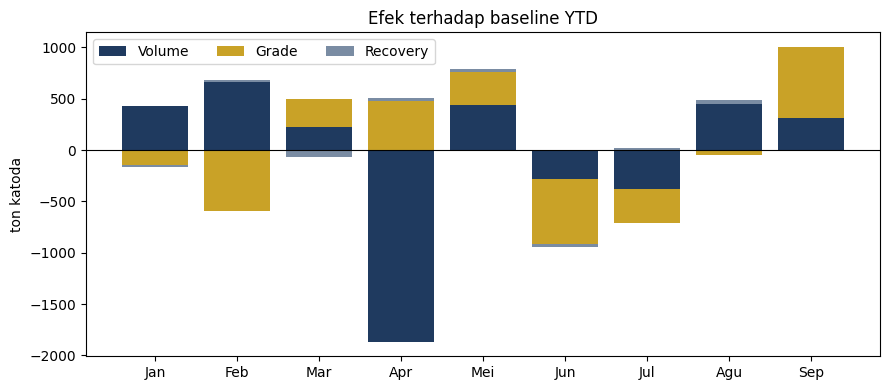

In [ ]:
D0 = h.Konsentrat_Masuk_DMT.sum() / len(h)                       # konsentrat per hari
g0 = h.Cu_Masuk_t.sum() / h.Konsentrat_Masuk_DMT.sum()           # grade Cu efektif (fraksi)
r0 = h.Katoda_Cu_t.sum() / h.Cu_Masuk_t.sum()                    # recovery (fraksi)
m = h.groupby("Bulan").agg(n=("Tanggal", "size"), d=("Konsentrat_Masuk_DMT", "sum"), cu=("Cu_Masuk_t", "sum"), kat=("Katoda_Cu_t", "sum"))
m["g"] = m.cu / m.d; m["r"] = m.kat / m.cu
m["Efek_Volume"] = (m.d - m.n * D0) * g0 * r0
m["Efek_Grade"] = m.d * (m.g - g0) * r0
m["Efek_Recovery"] = m.cu * (m.r - r0)
m["Total"] = m.kat - m.n * D0 * g0 * r0
print(m[["Efek_Volume", "Efek_Grade", "Efek_Recovery", "Total"]].round(1))
print("Cek identitas (selisih maks):", round((m.Efek_Volume + m.Efek_Grade + m.Efek_Recovery - m.Total).abs().max(), 10))

e = m[["Efek_Volume", "Efek_Grade", "Efek_Recovery"]]
fig, ax = plt.subplots(figsize=(9, 4))
bawah_p = np.zeros(len(e)); bawah_n = np.zeros(len(e))
for kol, wr in zip(e.columns, ["#1F3A5F", "#C9A227", "#7A8CA3"]):
    v = e[kol].values; bawah = np.where(v >= 0, bawah_p, bawah_n)
    ax.bar([NAMA_BULAN[i] for i in e.index], v, bottom=bawah, color=wr, label=kol.replace("Efek_", ""))
    bawah_p += np.where(v >= 0, v, 0); bawah_n += np.where(v < 0, v, 0)
ax.axhline(0, color="k", lw=.8); ax.set_ylabel("ton katoda"); ax.legend(ncol=3); ax.set_title("Efek terhadap baseline YTD")
plt.tight_layout(); plt.show()

## 5. Memperdalam: korelasi, pola hari, hubungan downtime–output

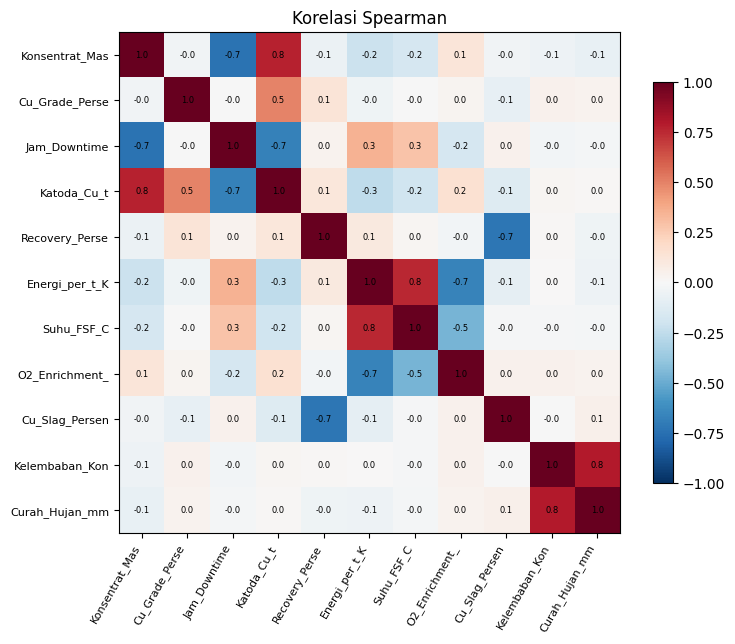

Korelasi terkuat dengan Energi per ton:
 Suhu_FSF_C              0.75
O2_Enrichment_Persen   -0.67
Jam_Downtime            0.35
Katoda_Cu_t            -0.26
Konsentrat_Masuk_DMT   -0.21
Name: Energi_per_t_Katoda_MWh, dtype: float64


In [ ]:
j = h.merge(pr, on="Tanggal")
kol = ["Konsentrat_Masuk_DMT", "Cu_Grade_Persen", "Jam_Downtime", "Katoda_Cu_t", "Recovery_Persen", "Energi_per_t_Katoda_MWh",
       "Suhu_FSF_C", "O2_Enrichment_Persen", "Cu_Slag_Persen", "Kelembaban_Konsentrat_Persen", "Curah_Hujan_mm"]
kor = j[kol].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kol))); ax.set_xticklabels([k[:14] for k in kol], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(kol))); ax.set_yticklabels([k[:14] for k in kol], fontsize=8)
for a in range(len(kol)):
    for b in range(len(kol)): ax.text(b, a, f"{kor.iloc[a, b]:.1f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, shrink=.8); ax.set_title("Korelasi Spearman"); plt.tight_layout(); plt.show()
print("Korelasi terkuat dengan Energi per ton:\n", kor["Energi_per_t_Katoda_MWh"].drop("Energi_per_t_Katoda_MWh").sort_values(key=abs, ascending=False).round(2).head(5))

In [ ]:
h["Hari"] = h.Tanggal.dt.day_name()
urut = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pola = h.groupby("Hari").agg(Rata_katoda=("Katoda_Cu_t", "mean"), Rata_downtime=("Jam_Downtime", "mean"),
                              Hari_downtime=("Jam_Downtime", lambda s: (s > 0).sum())).reindex(urut)
print(pola.round(2))
h["Ada_Downtime"] = h.Jam_Downtime > 0
print("\nRata-rata katoda: hari downtime vs normal")
print(h.groupby("Ada_Downtime").agg(n=("Tanggal", "size"), katoda=("Katoda_Cu_t", "mean"), energi_per_t=("Energi_per_t_Katoda_MWh", "mean")).round(3))

           Rata_katoda  Rata_downtime  Hari_downtime
Hari                                                
Monday          569.59           1.40             14
Tuesday         574.31           1.17              7
Wednesday       573.51           1.17              9
Thursday        569.12           1.15              9
Friday          577.18           1.12              9
Saturday        566.65           1.36             11
Sunday          577.99           1.09              8

Rata-rata katoda: hari downtime vs normal
                n   katoda  energi_per_t
Ada_Downtime                            
False         206  603.029         1.456
True           67  479.137         1.513


**Kesimpulan modul 1.**
(1) Katoda 156.326 t, 2,2% di atas target 153.000 t. Recovery 98,1%, availability 95,0%, Grade A 94,5% (258 dari 273 batch).
(2) Dengan target prorata, April paling buruk (−5,9%, downtime 102,5 jam) dan September paling baik (+8,1%).
(3) Lima penyebab henti teratas menyumbang 61,1% jam henti, dengan trip kompresor udara di urutan pertama (34 jam).
(4) Hari ada downtime memproduksi 479 t/hari, sedangkan hari normal 603 t/hari. Energi per ton juga lebih tinggi (1,513 vs 1,456).